# 03 - Model: patient-grouped split, logistic regression baseline, gradient boosting

**Input:** `data/processed/diabetic_clean.csv` (from notebook 02).
**Output:** two trained models in `models/`, the train/test assignment in `data/processed/split.csv`,
and ROC / PR curves in `reports/figures/`.

Plan:
1. Split **by patient** (no person in both train and test).
2. Build one preprocessing recipe (scale numbers, one-hot encode categories).
3. Baseline: logistic regression. Then: histogram gradient boosting (a fast tree ensemble).
4. Evaluate with ROC-AUC and PR-AUC (never accuracy alone), plus a confusion matrix.

Choosing the *decision threshold* by cost is notebook 04, so here we only look at the default 0.5 threshold
to see why it is a bad choice for rare events.

## 1. Setup and load

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score)

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT / "data" / "processed"
FIG = PROJECT / "reports" / "figures"
MODELS = PROJECT / "models"
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

SEED = 42          # fixed random seed = same split and same results every run
sns.set_theme(style="whitegrid")

df = pd.read_csv(PROCESSED / "diabetic_clean.csv",
                 dtype={"encounter_id": str, "patient_nbr": str})
df.shape

(99340, 34)

## 2. Features (X), target (y), groups
- `y` = what we predict (`readmit_30`).
- `groups` = `patient_nbr`, used **only** to keep each patient on one side of the split. It is not a feature.
- We drop `encounter_id` (a label, no meaning) and the `age` band (we use `age_num` instead; the band is kept in `df` for the fairness check later).

Text columns are **categorical**; number columns are **numeric**. In pandas 3 text columns have dtype `str`.

In [2]:
y = df["readmit_30"]
groups = df["patient_nbr"]
X = df.drop(columns=["encounter_id", "patient_nbr", "readmit_30", "age"])

cat_cols = X.select_dtypes("str").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()
assert len(cat_cols) + len(num_cols) == X.shape[1]

print(f"{len(num_cols)} numeric:", num_cols)
print(f"\n{len(cat_cols)} categorical:", cat_cols)

11 numeric: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'change', 'diabetesMed', 'age_num']

19 categorical: ['race', 'gender', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'admission_type', 'discharge_disposition', 'admission_source']


## 3. Train/test split grouped by patient
`StratifiedGroupKFold(n_splits=5)` cuts the data into 5 folds such that:
- **grouped**: all encounters of one patient land in the same fold, and
- **stratified**: each fold has roughly the same share of readmissions (~11.4%).

We take the first fold as the **test set (~20%)** and the other four as the **training set (~80%)**.
The test set is locked away: we look at it only to report final results, never to make choices.

In [3]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert len(overlap) == 0, "a patient appears in both train and test"

print(f"Train: {len(X_train):,} rows, {g_train.nunique():,} patients, base rate {y_train.mean():.2%}")
print(f"Test:  {len(X_test):,} rows, {groups.iloc[test_idx].nunique():,} patients, base rate {y_test.mean():.2%}")
print("Patients in both sets:", len(overlap))

Train: 79,472 rows, 55,969 patients, base rate 11.39%
Test:  19,868 rows, 14,018 patients, base rate 11.39%
Patients in both sets: 0


## 4. Preprocessing recipe
A `ColumnTransformer` applies different steps to different columns:
- **numeric -> `StandardScaler`**: rescales each column to mean 0, standard deviation 1. Logistic regression needs this so a column
  measured in large units (lab procedures, up to 132) doesn't dominate one in small units (emergency visits).
- **categorical -> `OneHotEncoder`**: turns `race = "Asian"` into a 0/1 column `race_Asian`. `handle_unknown="ignore"` means a category
  never seen in training becomes all zeros instead of crashing.

Putting preprocessing *inside* a `Pipeline` matters: the scaler learns its mean/std **from training data only**.
If we scaled the whole dataset first, test-set information would leak into training.

In [4]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

n_features = make_preprocessor().fit(X_train).transform(X_train.head()).shape[1]
print(f"{X.shape[1]} raw columns -> {n_features} model columns after one-hot encoding")

30 raw columns -> 120 model columns after one-hot encoding


## 5. Two reference points before any model
- **Random guessing** gives ROC-AUC = 0.50.
- **PR-AUC of random guessing = the base rate** (~0.114), because if you flag patients at random, the share who are truly readmitted
  equals the overall share.

Any model must beat these to be worth anything.

**About imbalance:** we do *not* reweight classes (`class_weight="balanced"`). Reweighting distorts predicted probabilities;
we keep honest probabilities and handle the imbalance by choosing the decision threshold in notebook 04.

In [5]:
base_rate = y_test.mean()
print(f"Random ROC-AUC: 0.500   Random PR-AUC (= test base rate): {base_rate:.3f}")

Random ROC-AUC: 0.500   Random PR-AUC (= test base rate): 0.114


## 6. Baseline: logistic regression
Logistic regression computes a weighted sum of the features and squeezes it through the sigmoid function into a probability
between 0 and 1. It is simple, fast and easy to explain, which makes it the right first model.

**Cross-validation on the training set** (5 grouped folds) shows how stable the score is: train on 4 folds, score on the 5th, repeat.
This uses only training data; the test set stays untouched.

In [6]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

logreg = Pipeline([
    ("pre", make_preprocessor()),
    ("model", LogisticRegression(max_iter=2000)),
])

cv_auc_lr = cross_val_score(logreg, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc")
print("CV ROC-AUC per fold:", cv_auc_lr.round(3), f"  mean {cv_auc_lr.mean():.3f} +/- {cv_auc_lr.std():.3f}")

logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]     # column 1 = probability of class 1 (readmitted)
print(f"TEST ROC-AUC {roc_auc_score(y_test, p_lr):.3f}   PR-AUC {average_precision_score(y_test, p_lr):.3f}")

CV ROC-AUC per fold: [0.654 0.66  0.658 0.66  0.654]   mean 0.657 +/- 0.003
TEST ROC-AUC 0.670   PR-AUC 0.218


## 7. Tree model: histogram gradient boosting
Gradient boosting builds many small decision trees **one after another**; each new tree focuses on the errors of the trees before it.
It can capture interactions (e.g. "many prior visits *and* discharged to a nursing facility") that a linear model cannot.

`HistGradientBoostingClassifier` is scikit-learn's fast version. With more than 10,000 rows it uses **early stopping**:
it holds back 10% of the training data internally and stops adding trees once that score stops improving, which limits overfitting.

In [7]:
hgb = Pipeline([
    ("pre", make_preprocessor()),
    ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, random_state=SEED)),
])

cv_auc_hgb = cross_val_score(hgb, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc")
print("CV ROC-AUC per fold:", cv_auc_hgb.round(3), f"  mean {cv_auc_hgb.mean():.3f} +/- {cv_auc_hgb.std():.3f}")

hgb.fit(X_train, y_train)
p_hgb = hgb.predict_proba(X_test)[:, 1]
print("Trees used after early stopping:", hgb.named_steps["model"].n_iter_)
print(f"TEST ROC-AUC {roc_auc_score(y_test, p_hgb):.3f}   PR-AUC {average_precision_score(y_test, p_hgb):.3f}")

CV ROC-AUC per fold: [0.665 0.667 0.67  0.671 0.661]   mean 0.667 +/- 0.003
Trees used after early stopping: 125
TEST ROC-AUC 0.678   PR-AUC 0.237


## 8. Compare
**ROC-AUC**: the probability that a randomly chosen readmitted patient gets a higher score than a randomly chosen non-readmitted one.
**PR-AUC**: average precision across all thresholds; more informative when positives are rare. Compare it to the base rate:
`lift = PR-AUC / base rate` says how many times better than random the model ranks patients.

In [8]:
results = pd.DataFrame({
    "model": ["Random", "Logistic regression", "Gradient boosting"],
    "cv_roc_auc_mean": [0.5, cv_auc_lr.mean(), cv_auc_hgb.mean()],
    "test_roc_auc": [0.5, roc_auc_score(y_test, p_lr), roc_auc_score(y_test, p_hgb)],
    "test_pr_auc": [base_rate, average_precision_score(y_test, p_lr), average_precision_score(y_test, p_hgb)],
})
results["pr_lift_vs_random"] = results["test_pr_auc"] / base_rate
results.round(3)

,model,cv_roc_auc_mean,test_roc_auc,test_pr_auc,pr_lift_vs_random
0,Random,0.500,0.500,0.114,1.000
1,Logistic regression,0.657,0.670,0.218,1.910
2,Gradient boosting,0.667,0.678,0.237,2.084


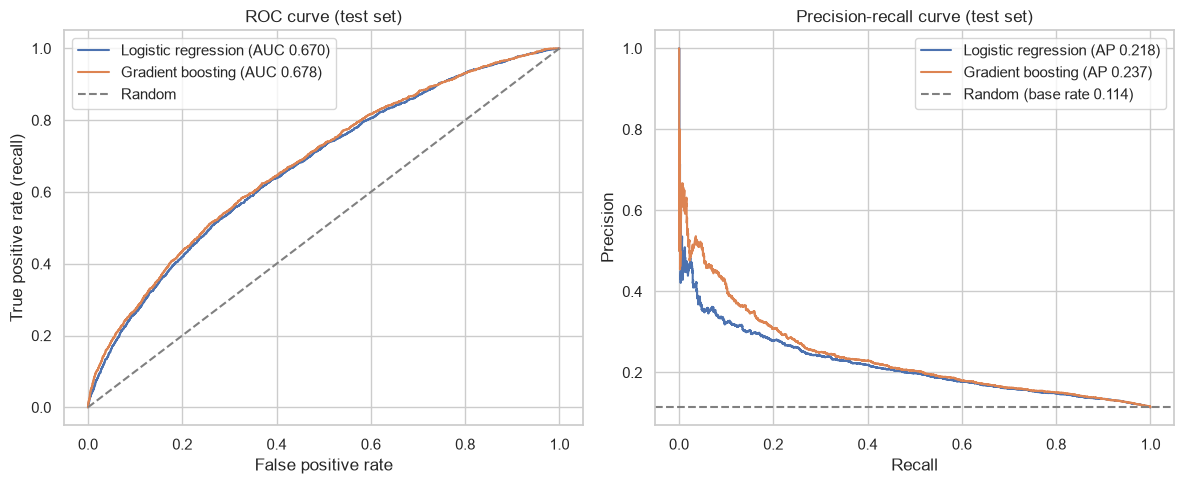

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in [("Logistic regression", p_lr), ("Gradient boosting", p_hgb)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="Random")
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].axhline(base_rate, ls="--", color="grey", label=f"Random (base rate {base_rate:.3f})")
axes[1].set(title="Precision-recall curve (test set)", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(loc="best")
plt.tight_layout()
plt.savefig(FIG / "03_roc_pr_curves.png", dpi=150)
plt.show()

## 9. Why the default 0.5 threshold fails here
`predict()` labels a patient "readmitted" only if the probability is above 0.5. With an 11% base rate, almost nobody gets a score
that high, so the model flags almost no one: high accuracy, near-zero recall, useless for a hospital.

In [10]:
def report_at(p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"threshold": threshold, "flagged": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "recall": recall_score(y_test, pred, zero_division=0),
            "precision": precision_score(y_test, pred, zero_division=0),
            "accuracy": (tp + tn) / len(pred)}

pd.DataFrame([
    {"model": "Logistic regression", **report_at(p_lr, 0.5)},
    {"model": "Gradient boosting", **report_at(p_hgb, 0.5)},
    {"model": "Always 'not readmitted'", "threshold": None, "flagged": 0, "TP": 0, "FP": 0,
     "FN": int(y_test.sum()), "TN": int((y_test == 0).sum()), "recall": 0.0, "precision": 0.0,
     "accuracy": 1 - base_rate},
]).round(3)

,model,threshold,flagged,TP,FP,FN,TN,recall,precision,accuracy
0,Logistic regression,0.5,57,28,29,2235,17576,0.012,0.491,0.886
1,Gradient boosting,0.5,46,28,18,2235,17587,0.012,0.609,0.887
2,Always 'not readmitted',NaN,0,0,0,2263,17605,0.000,0.000,0.886


**Read this table carefully:** both models are about as "accurate" as a rule that never flags anyone, yet that rule catches zero
readmissions. That is exactly why we never report accuracy alone. Notebook 04 picks a threshold based on the cost of a missed
readmission versus an unnecessary follow-up call.

## 10. Save models, split and test predictions
`joblib.dump` saves the whole fitted pipeline (preprocessing + model) to one file, so later notebooks load it instead of retraining.

In [11]:
joblib.dump(logreg, MODELS / "logreg.joblib")
joblib.dump(hgb, MODELS / "hgb.joblib")

split = pd.DataFrame({"encounter_id": df["encounter_id"], "set": "train"})
split.loc[split.index[test_idx], "set"] = "test"
split.to_csv(PROCESSED / "split.csv", index=False)

print(split["set"].value_counts())
print("Saved:", sorted(p.name for p in MODELS.glob("*.joblib")))

set
train    79472
test     19868
Name: count, dtype: int64
Saved: ['hgb.joblib', 'logreg.joblib']


## 11. Note on performance
ROC-AUC around 0.67-0.68 is modest. 30-day readmission depends on many things that are not in this data
(social support, access to follow-up care, medication adherence), which limits how well any model can rank patients.